# GitSkills — data analysis

Uses the CSV files built by `data_cleaning.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

skills = pd.read_csv(DATA_DIR / "skills_copied.csv")
repos = pd.read_csv(DATA_DIR / "repos_clean.csv")
adoptions = pd.read_csv(DATA_DIR / "adoptions.csv")

## RQ1 — Do copied skills cross language boundaries?

We keep skills copied by at least 2 eligible owners, with one row per skill and owner. If an
owner has the skill in several repositories, we keep their most frequent language.

A skill is `cross_language` if its owners use more than one primary language, `siloed` otherwise.

In [2]:
rq1_ids = skills.loc[skills["n_owners_eligible"] >= 2, "skill_id"]
eligible_repos = repos.loc[repos["eligible"] == 1, ["repo_id", "owner", "language"]]

owner_adoptions = (adoptions[adoptions["skill_id"].isin(rq1_ids)]
                   .merge(eligible_repos, on="repo_id")
                   .groupby(["skill_id", "owner", "language"]).size().rename("n")
                   .reset_index()
                   .sort_values("n", ascending=False, kind="stable")
                   .drop_duplicates(["skill_id", "owner"]))

rq1 = owner_adoptions.groupby("skill_id").agg(
    n_owners=("owner", "size"), n_languages=("language", "nunique"))
rq1["spread_class"] = "siloed"
rq1.loc[rq1["n_languages"] > 1, "spread_class"] = "cross_language"
rq1["adopters"] = pd.cut(rq1["n_owners"], [1, 2, 5, 20, np.inf], labels=["2", "3-5", "6-20", ">20"])

print(f"{len(rq1):,} skills")
pd.crosstab(rq1["adopters"], rq1["spread_class"], normalize="index", margins=True).round(3)

67,061 skills


spread_class,cross_language,siloed
adopters,,
2,0.410,0.590
3-5,0.646,0.354
6-20,0.840,0.160
>20,0.994,0.006
All,0.576,0.424


### Comparison with chance

Most owners use TypeScript or Python, so even two random owners often use different
languages. To know if the observed crossing rate is high or low, we compare it to
what we would see if language played no role: we shuffle the languages of the skill/owner
rows at random and recompute the rate, 1,000 times.

If the observed rate is below the expected one, skills tend to stay within their language.

In [3]:
N_PERMUTATIONS = 1000
rng = np.random.default_rng(42)

skill_codes, _ = pd.factorize(owner_adoptions["skill_id"])
language_codes, _ = pd.factorize(owner_adoptions["language"])
adopters = rq1["adopters"].reindex(owner_adoptions["skill_id"].unique()).to_numpy()


def crossing_rate(language):
    # Share of skills found in more than one language, per adopters group and overall
    crosses = pd.Series(language).groupby(skill_codes).nunique() > 1
    rates = crosses.groupby(adopters, observed=True).mean()
    rates["all"] = crosses.mean()
    return rates


observed = crossing_rate(language_codes)
expected = pd.concat([crossing_rate(rng.permutation(language_codes))
                      for _ in range(N_PERMUTATIONS)], axis=1)

results = pd.DataFrame({
    "observed": observed,
    "expected": expected.mean(axis=1),
    "p_value": ((expected.T <= observed).sum() + 1) / (N_PERMUTATIONS + 1),
}).round(3).rename_axis("adopters").reset_index()
results

,adopters,observed,expected,p_value
0,2,0.410,0.762,0.001
1,3-5,0.646,0.953,0.001
2,6-20,0.840,0.999,0.001
3,>20,0.994,1.000,0.001
4,all,0.576,0.870,0.001


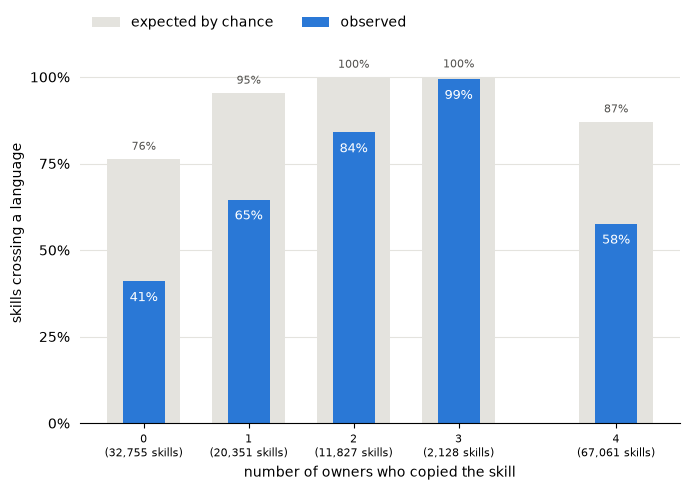

In [4]:
n_skills = list(rq1["adopters"].value_counts().sort_index()) + [len(rq1)]
labels = [f"{group}\n({n:,} skills)" for group, n in zip(results.index, n_skills)]
x = np.array([0, 1, 2, 3, 4.5])  # small gap before "all"

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x, results["expected"], width=0.7, color="#e4e3de", label="expected by chance")
ax.bar(x, results["observed"], width=0.4, color="#2a78d6", label="observed")
for xi, obs, exp in zip(x, results["observed"], results["expected"]):
    ax.text(xi, obs - 0.03, f"{obs:.0%}", ha="center", va="top", fontsize=9, color="white")
    ax.text(xi, exp + 0.02, f"{exp:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")

ax.set_xticks(x, labels, fontsize=8)
ax.set_xlabel("number of owners who copied the skill")
ax.set_ylabel("skills crossing a language")
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.grid(True, color="#e4e3de", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_language_crossing.pdf")
plt.show()

### Which languages share skills?

For each skill, every pair of its owners gives a pair of languages. We count these pairs
(weighted by 1 / (number of owners − 1) so that very popular skills do not dominate) and
divide by the count expected if owners were paired at random. Above 1 means the two languages
share more skills than chance. On the other side, below 1 mean less. Only the 12 largest languages are shown.

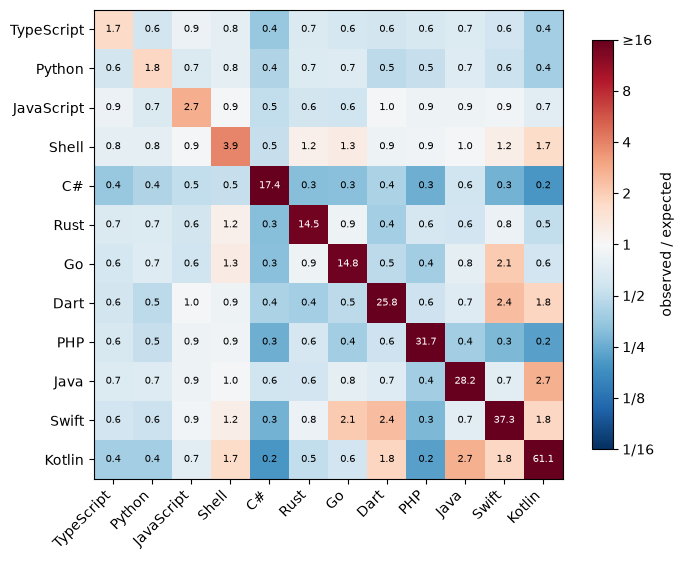

In [5]:
counts = pd.crosstab(owner_adoptions["skill_id"], owner_adoptions["language"])
C = counts.to_numpy()
weighted = C / (C.sum(axis=1, keepdims=True) - 1)

pairs = weighted.T @ C - np.diag(weighted.sum(axis=0))
totals = C.sum(axis=0)
ratio = pd.DataFrame(pairs / np.outer(totals, totals) * totals.sum(),
                     index=counts.columns, columns=counts.columns)

top = owner_adoptions["language"].value_counts().index[:12]
ratio = ratio.loc[top, top]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-4, vmax=4)
for i in range(len(top)):
    for j in range(len(top)):
        color = "white" if ratio.iat[i, j] > 6 else "black"
        ax.text(j, i, f"{ratio.iat[i, j]:.1f}", ha="center", va="center", fontsize=7, color=color)
ax.set_xticks(range(len(top)), top, rotation=45, ha="right")
ax.set_yticks(range(len(top)), top)
bar = fig.colorbar(im, ax=ax, shrink=0.8, ticks=range(-4, 5))
bar.ax.set_yticklabels(["1/16", "1/8", "1/4", "1/2", "1", "2", "4", "8", "≥16"])
bar.set_label("observed / expected")
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_language_heatmap.pdf")
plt.show()

Small languages get large ratios easily, so we also look at the plain share of a
language's co-adopters that use the same language, compared to its share of all adoptions.

In [6]:
pd.DataFrame({
    "share_of_adoptions": totals / totals.sum(),
    "same_language_share": np.diag(pairs) / totals,
}, index=counts.columns).loc[top].round(3)

,share_of_adoptions,same_language_share
language,,
TypeScript,0.336,0.570
Python,0.324,0.578
JavaScript,0.120,0.328
Shell,0.051,0.196
C#,0.032,0.554
Rust,0.023,0.329
Go,0.022,0.326
Dart,0.014,0.357
PHP,0.013,0.397


## RQ2 — What distinguishes universal skills from siloed ones?

Skills copied by at least 3 eligible owners are `universal` if their owners use at least 3
languages and `siloed` if they all use the same one. Skills with exactly 2 languages are left out.

In [7]:
rq2 = rq1[(rq1["n_owners"] >= 3) & (rq1["n_languages"] != 2)].copy()
rq2["group"] = np.where(rq2["n_languages"] == 1, "siloed", "universal")

pd.crosstab(rq2["adopters"], rq2["group"])

group,siloed,universal
adopters,,
3-5,7201,5062
6-20,1891,7153
>20,12,1971


Universal skills are also more popular. To compare skills of equal popularity, for each number of
owners we keep as many universal as siloed skills, picked at random.

In [8]:
shuffled = rq2.sample(frac=1, random_state=42)
rank = shuffled.groupby(["n_owners", "group"]).cumcount()
n_kept = shuffled.groupby(["n_owners", "group"]).size().unstack(fill_value=0).min(axis=1)
matched = shuffled[rank < shuffled["n_owners"].map(n_kept)].join(skills.set_index("skill_id")[
    ["body_chars", "frontmatter_valid", "has_scripts", "has_references", "code_languages", "topic"]])

matched.groupby("group")["n_owners"].agg(["size", "mean"])

,size,mean
group,,
siloed,6678,5.096436
universal,6678,5.096436


### Characteristics

Each characteristic is compared with a Mann-Whitney U test, and Cliff's delta measures how big the
difference is (positive: higher for universal skills). `text length` is a mean, the other values are
shares.

Thresholds on the absolute delta: negligible < 0.147, small < 0.33, medium < 0.474, large above.

In [9]:
from scipy.stats import chi2_contingency, mannwhitneyu

features = pd.DataFrame({
    "group": matched["group"],
    "text length": matched["body_chars"],
    "valid front matter": matched["frontmatter_valid"],
    "has reference files": matched["has_references"],
    "has scripts": matched["has_scripts"],
    "has code": matched["code_languages"].notna().astype(int),
})

rows = []
for feature in features.columns.drop("group"):
    data = features.dropna(subset=[feature])
    universal = data.loc[data["group"] == "universal", feature]
    siloed = data.loc[data["group"] == "siloed", feature]
    u, p_value = mannwhitneyu(universal, siloed)
    rows.append({"feature": feature, "siloed": siloed.mean(), "universal": universal.mean(),
                 "cliffs_delta": 2 * u / (len(universal) * len(siloed)) - 1,
                 "p_value": min(p_value * 5, 1)})

characteristics = pd.DataFrame(rows).set_index("feature")
characteristics["magnitude"] = pd.cut(characteristics["cliffs_delta"].abs(), [0, 0.147, 0.33, 0.474, 1],
                                      labels=["negligible", "small", "medium", "large"], right=False)
characteristics.round({"siloed": 3, "universal": 3, "cliffs_delta": 3})

,siloed,universal,cliffs_delta,p_value,magnitude
feature,,,,,
text length,10652.227,9253.555,-0.010,1.000000e+00,negligible
valid front matter,0.953,0.978,0.025,2.190606e-14,negligible
has reference files,0.359,0.362,0.003,1.000000e+00,negligible
has scripts,0.177,0.089,-0.088,2.427283e-50,negligible
has code,0.630,0.496,-0.134,2.247166e-54,negligible


Share of skills with code in each language:

In [10]:
by_language = matched.assign(language=matched["code_languages"].str.split(";")).explode("language")
code_languages = pd.crosstab(by_language["language"], by_language["group"]) / matched["group"].value_counts()
code_languages.sort_values("siloed", ascending=False).head(8).round(3)

group,siloed,universal
language,,
Shell,0.490,0.353
Python,0.110,0.064
TypeScript,0.109,0.084
JavaScript,0.033,0.052
Dart,0.009,0.004
PowerShell,0.007,0.014
PHP,0.006,0.007
Go,0.006,0.010


### Topics

Chi² test on the topic × group table, with Cramér's V to measure how big the difference is.
Cramér's V ≥ 0.1 is small, ≥ 0.3 medium, ≥ 0.5 large.

In [11]:
topic_counts = pd.crosstab(matched["topic"], matched["group"])
chi2, p_value, _, _ = chi2_contingency(topic_counts)
print(f"chi2 = {chi2:.0f}, p = {p_value:.1e}, Cramer's V = {np.sqrt(chi2 / len(matched)):.3f}")

topics = topic_counts / topic_counts.sum()
topics.sort_values("siloed").round(3)

chi2 = 306, p = 2.4e-58, Cramer's V = 0.151


group,siloed,universal
topic,,
mcp / search / composio,0.031,0.022
security / azure / audit,0.038,0.049
none,0.038,0.014
commit / pr / git,0.053,0.040
test / testing / tests,0.063,0.057
agent / agents / multi,0.075,0.060
skill / skills / new,0.077,0.064
review / code / quality,0.084,0.094
api / documentation / rest,0.085,0.079


### Figure

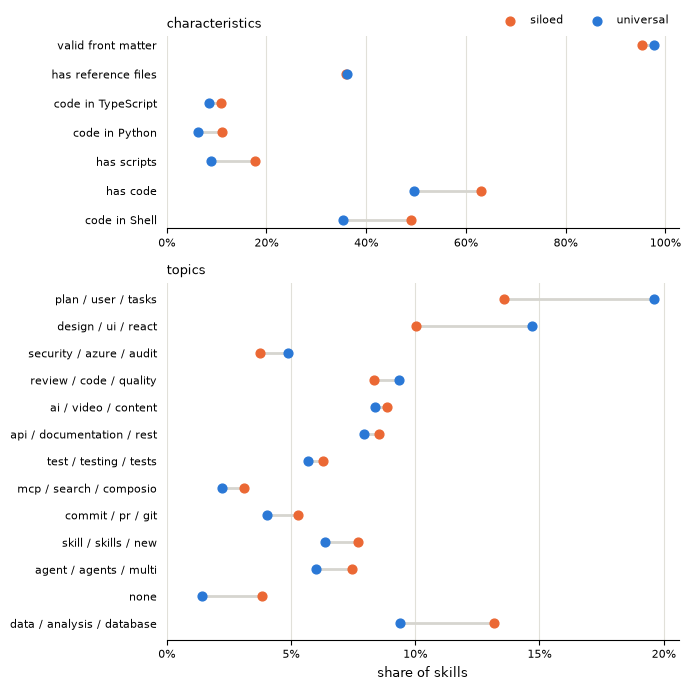

In [12]:
shares = pd.concat([
    characteristics.drop("text length")[["siloed", "universal"]],
    code_languages.loc[["Shell", "Python", "TypeScript"]].rename(index=lambda l: f"code in {l}"),
])

fig, axes = plt.subplots(2, 1, figsize=(7, 7), height_ratios=[len(shares), len(topics)])
for ax, table, step, title in [(axes[0], shares, 0.2, "characteristics"), (axes[1], topics, 0.05, "topics")]:
    table = table.loc[(table["universal"] - table["siloed"]).sort_values().index]
    y = np.arange(len(table))
    ax.hlines(y, table["siloed"], table["universal"], color="#d6d5cf", linewidth=2)
    ax.scatter(table["siloed"], y, s=40, color="#eb6834", zorder=2, label="siloed")
    ax.scatter(table["universal"], y, s=40, color="#2a78d6", zorder=2, label="universal")
    ax.set_yticks(y, table.index, fontsize=8)
    ax.set_xlim(0, table.to_numpy().max() * 1.05)
    ax.xaxis.set_major_locator(plt.MultipleLocator(step))
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.xaxis.grid(True, color="#e1e0d9")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(left=False, labelsize=8)
    ax.set_title(title, loc="left", fontsize=9)

axes[0].legend(frameon=False, ncol=2, fontsize=8, loc="lower right", bbox_to_anchor=(1, 1))
axes[1].set_xlabel("share of skills", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "rq2_characteristics.pdf")
plt.show()

### Interpretation

At equal popularity, the structure of universal and siloed skills is the same. Siloed skills more
often contain code (63.0% vs. 49.6%) and scripts (17.7% vs. 8.9%), and more often deal with data and
databases or have no English description. Universal skills are more often about planning tasks
(19.6% vs. 13.6%) and UI design (14.7% vs. 10.0%), work that does not depend on the project's
language. These effects are small (Cramér's V = 0.15) or negligible: what a skill contains explains
only part of the siloing found in RQ1.